# MNIST ile MLP Tabanlı El Yazısı Rakam Tanıma

**Öğrenci No:** 23120205027

Bu notebook şunları yapar:
1. MNIST'i **train / validation / test** olarak ayırır (test verisi model geliştirmede kullanılmaz).
2. **Deney 1:** Temel MLP (2 hidden layer, ReLU, CrossEntropyLoss, Adam) eğitir; loss/accuracy, test accuracy ve eğitim süresini raporlar, grafikleri çizer.
3. **Deney 2:** Farklı hiperparametre yapılandırmalarını karşılaştırır (model seçimi yalnızca validation accuracy ile yapılır).
4. Kendi el yazımla yazdığım okul numarasını MNIST formatına getirip (gri ton, 28×28, siyah arka plan / beyaz rakam, normalizasyon) modele verir.

> Colab'da: `Çalışma zamanı → Çalışma zamanı türünü değiştir → T4 GPU` seçilirse daha hızlı çalışır (CPU'da da çalışır).

In [1]:
import os, time, random, copy
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torchvision import datasets
from PIL import Image, ImageFilter
from scipy import ndimage

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Cihaz:", device)

Cihaz: cuda


## 1. Veri Seti ve Train / Validation / Test Ayrımı

- MNIST'in resmi **60.000** görüntülük eğitim kümesi → **50.000 train + 10.000 validation** (sabit seed ile rastgele bölme).
- MNIST'in resmi **10.000** görüntülük test kümesi → **test** (sadece en sonda, bir kez değerlendirme için).
- Ön işleme: piksel değerleri [0,1] aralığına ölçeklenir, ardından MNIST ortalama/std'si ile normalize edilir: `(x - 0.1307) / 0.3081`.
- MLP girdisi: 28×28 görüntü → 784 boyutlu vektör (flatten).

100%|██████████| 9.91M/9.91M [00:00<00:00, 20.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 495kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.65MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.94MB/s]


Train: 50000 | Validation: 10000 | Test: 10000


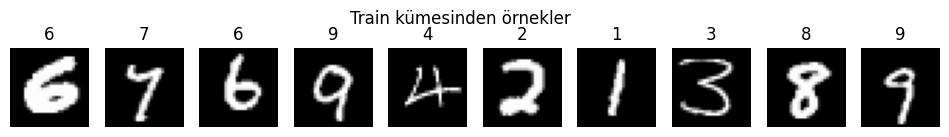

In [2]:
MNIST_MEAN, MNIST_STD = 0.1307, 0.3081

train_full = datasets.MNIST("data", train=True, download=True)
test_set   = datasets.MNIST("data", train=False, download=True)

def to_tensor(ds):
    x = ds.data.float() / 255.0                 # [N, 28, 28], 0..1
    x = (x - MNIST_MEAN) / MNIST_STD            # normalizasyon
    return x.view(len(x), -1), ds.targets.clone()   # [N, 784]

X_full, y_full = to_tensor(train_full)
X_test, y_test = to_tensor(test_set)

g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(len(X_full), generator=g)
train_idx, val_idx = perm[:50_000], perm[50_000:]

X_train, y_train = X_full[train_idx].to(device), y_full[train_idx].to(device)
X_val,   y_val   = X_full[val_idx].to(device),   y_full[val_idx].to(device)
X_test,  y_test  = X_test.to(device),            y_test.to(device)

print(f"Train: {len(X_train)} | Validation: {len(X_val)} | Test: {len(X_test)}")

fig, axes = plt.subplots(1, 10, figsize=(12, 1.6))
for i, ax in enumerate(axes):
    ax.imshow(train_full.data[train_idx[i]], cmap="gray"); ax.set_title(int(y_full[train_idx[i]])); ax.axis("off")
plt.suptitle("Train kümesinden örnekler"); plt.show()

## 2. Model ve Eğitim Fonksiyonları

MLP: `784 → hidden_1 → ReLU → ... → hidden_k → ReLU → 10`. Çıkışta softmax yok; `nn.CrossEntropyLoss` softmax + negative log-likelihood'u kendi içinde uygular.

Her epoch sonunda validation accuracy ölçülür ve **en iyi validation accuracy'e sahip ağırlıklar** saklanır (model seçimi test verisine bakılmadan yapılır).

In [3]:
class MLP(nn.Module):
    def __init__(self, hidden_sizes=(256, 128), dropout=0.0, in_dim=784, n_classes=10):
        super().__init__()
        layers, prev = [], in_dim
        for h in hidden_sizes:
            layers += [nn.Linear(prev, h), nn.ReLU()]
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            prev = h
        layers.append(nn.Linear(prev, n_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x.view(x.size(0), -1))


@torch.no_grad()
def evaluate(model, X, y, batch_size=2048):
    model.eval()
    loss_fn = nn.CrossEntropyLoss(reduction="sum")
    total_loss, correct = 0.0, 0
    for i in range(0, len(X), batch_size):
        out = model(X[i:i + batch_size])
        total_loss += loss_fn(out, y[i:i + batch_size]).item()
        correct += (out.argmax(1) == y[i:i + batch_size]).sum().item()
    return total_loss / len(X), correct / len(X)


def train_model(cfg, verbose=True):
    set_seed(cfg.get("seed", SEED))
    model = MLP(cfg["hidden"], cfg.get("dropout", 0.0)).to(device)
    if cfg["optimizer"] == "adam":
        opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"], weight_decay=cfg.get("weight_decay", 0.0))
    else:
        opt = torch.optim.SGD(model.parameters(), lr=cfg["lr"], momentum=cfg.get("momentum", 0.0),
                              weight_decay=cfg.get("weight_decay", 0.0))
    loss_fn = nn.CrossEntropyLoss()
    hist = {k: [] for k in ["train_loss", "val_loss", "train_acc", "val_acc"]}
    best_val, best_state, best_epoch = -1.0, None, 0
    bs, n = cfg["batch_size"], len(X_train)

    if device.type == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    for epoch in range(1, cfg["epochs"] + 1):
        model.train()
        idx = torch.randperm(n, device=device)
        run_loss, run_correct = 0.0, 0
        for i in range(0, n, bs):
            b = idx[i:i + bs]
            xb, yb = X_train[b], y_train[b]
            out = model(xb)
            loss = loss_fn(out, yb)
            opt.zero_grad()
            loss.backward()
            opt.step()
            run_loss += loss.item() * len(b)
            run_correct += (out.argmax(1) == yb).sum().item()
        tr_loss, tr_acc = run_loss / n, run_correct / n
        va_loss, va_acc = evaluate(model, X_val, y_val)
        for k, v in zip(hist, [tr_loss, va_loss, tr_acc, va_acc]):
            hist[k].append(v)
        if va_acc > best_val:
            best_val, best_epoch = va_acc, epoch
            best_state = copy.deepcopy(model.state_dict())
        if verbose:
            print(f"Epoch {epoch:2d}/{cfg['epochs']} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
                  f"val loss {va_loss:.4f} acc {va_acc:.4f}")
    if device.type == "cuda": torch.cuda.synchronize()
    train_time = time.time() - t0

    model.load_state_dict(best_state)
    return model, hist, train_time, best_epoch


def plot_history(hist, title=""):
    ep = range(1, len(hist["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(ep, hist["train_loss"], "o-", label="Train loss")
    ax[0].plot(ep, hist["val_loss"], "s-", label="Validation loss")
    ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Loss"); ax[0].set_title(f"{title} – Loss"); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].plot(ep, hist["train_acc"], "o-", label="Train accuracy")
    ax[1].plot(ep, hist["val_acc"], "s-", label="Validation accuracy")
    ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Accuracy"); ax[1].set_title(f"{title} – Accuracy"); ax[1].legend(); ax[1].grid(alpha=.3)
    plt.tight_layout(); plt.show()

## 3. Deney 1 – Temel MLP Modeli

| Hiperparametre | Değer |
|---|---|
| Mimari | 784 → 256 → 128 → 10 (2 hidden layer) |
| Aktivasyon | ReLU |
| Loss | CrossEntropyLoss |
| Optimizer | Adam |
| Learning rate | 0.001 |
| Batch size | 128 |
| Epoch | 20 |
| Dropout / weight decay | yok |
| Seed | 42 |

Epoch  1/20 | train loss 0.2975 acc 0.9127 | val loss 0.1577 acc 0.9520
Epoch  2/20 | train loss 0.1140 acc 0.9659 | val loss 0.1224 acc 0.9629
Epoch  3/20 | train loss 0.0739 acc 0.9773 | val loss 0.0950 acc 0.9682
Epoch  4/20 | train loss 0.0541 acc 0.9824 | val loss 0.0874 acc 0.9720
Epoch  5/20 | train loss 0.0401 acc 0.9875 | val loss 0.1004 acc 0.9699
Epoch  6/20 | train loss 0.0342 acc 0.9885 | val loss 0.0838 acc 0.9747
Epoch  7/20 | train loss 0.0255 acc 0.9917 | val loss 0.1054 acc 0.9722
Epoch  8/20 | train loss 0.0243 acc 0.9918 | val loss 0.0862 acc 0.9756
Epoch  9/20 | train loss 0.0171 acc 0.9943 | val loss 0.1007 acc 0.9752
Epoch 10/20 | train loss 0.0181 acc 0.9939 | val loss 0.1112 acc 0.9725
Epoch 11/20 | train loss 0.0178 acc 0.9938 | val loss 0.0996 acc 0.9753
Epoch 12/20 | train loss 0.0130 acc 0.9953 | val loss 0.1044 acc 0.9757
Epoch 13/20 | train loss 0.0132 acc 0.9953 | val loss 0.1168 acc 0.9752
Epoch 14/20 | train loss 0.0130 acc 0.9954 | val loss 0.1210 acc

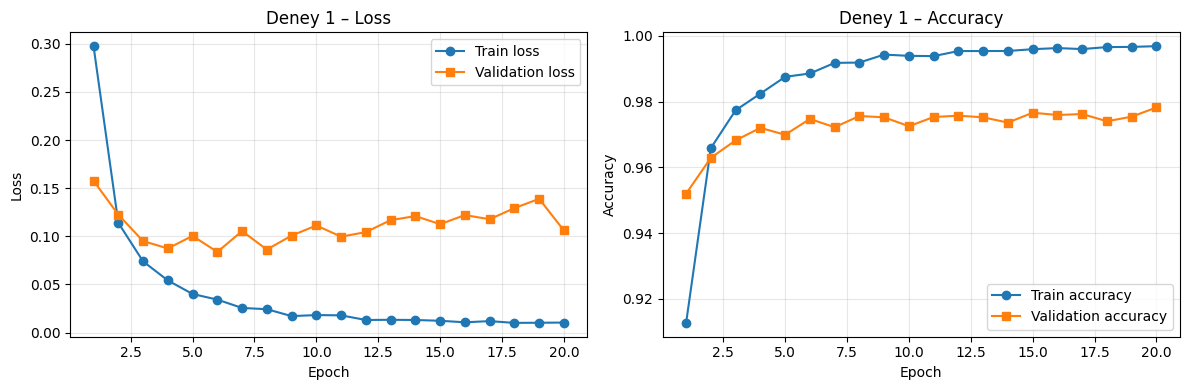

In [4]:
BASE_CFG = dict(name="Temel MLP", hidden=(256, 128), optimizer="adam", lr=1e-3,
                batch_size=128, epochs=20, dropout=0.0)

base_model, base_hist, base_time, base_best_epoch = train_model(BASE_CFG)
plot_history(base_hist, "Deney 1")

### Deney 1 Sonuçları
Validation'a göre en iyi epoch'taki ağırlıklar seçildi. **Test accuracy sadece burada, bir kez hesaplanır.**

In [5]:
e = base_best_epoch - 1
base_test_loss, base_test_acc = evaluate(base_model, X_test, y_test)
n_params = sum(p.numel() for p in base_model.parameters())

print(f"Parametre sayısı      : {n_params:,}")
print(f"Seçilen epoch         : {base_best_epoch}")
print(f"Training loss         : {base_hist['train_loss'][e]:.4f}")
print(f"Validation loss       : {base_hist['val_loss'][e]:.4f}")
print(f"Training accuracy     : {base_hist['train_acc'][e]*100:.2f}%")
print(f"Validation accuracy   : {base_hist['val_acc'][e]*100:.2f}%")
print(f"Test accuracy         : {base_test_acc*100:.2f}%")
print(f"Eğitim süresi         : {base_time:.1f} sn ({device})")
print(f"Son epoch train/val loss: {base_hist['train_loss'][-1]:.4f} / {base_hist['val_loss'][-1]:.4f}")

Parametre sayısı      : 235,146
Seçilen epoch         : 20
Training loss         : 0.0104
Validation loss       : 0.1060
Training accuracy     : 99.68%
Validation accuracy   : 97.82%
Test accuracy         : 97.94%
Eğitim süresi         : 14.1 sn (cuda)
Son epoch train/val loss: 0.0104 / 0.1060


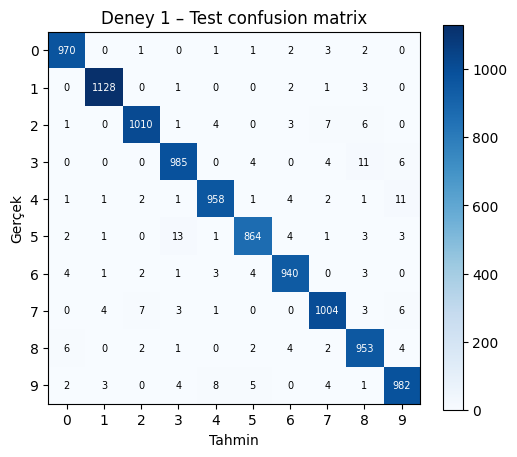

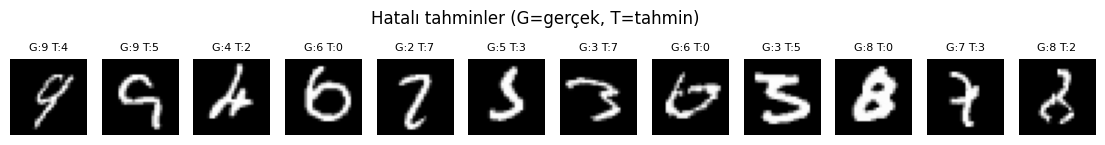

In [6]:
# Test kümesinde confusion matrix ve hatalı tahmin örnekleri
@torch.no_grad()
def predict_all(model, X):
    model.eval()
    return torch.cat([model(X[i:i+4096]).argmax(1) for i in range(0, len(X), 4096)])

pred = predict_all(base_model, X_test).cpu()
yt = y_test.cpu()
cm = torch.zeros(10, 10, dtype=torch.long)
for t, p in zip(yt, pred):
    cm[t, p] += 1

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap="Blues")
for i in range(10):
    for j in range(10):
        ax.text(j, i, int(cm[i, j]), ha="center", va="center", fontsize=7,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xlabel("Tahmin"); ax.set_ylabel("Gerçek"); ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_title("Deney 1 – Test confusion matrix"); plt.colorbar(im); plt.show()

wrong = (pred != yt).nonzero().flatten()[:12]
fig, axes = plt.subplots(1, len(wrong), figsize=(14, 1.8))
for ax, i in zip(axes, wrong):
    ax.imshow(test_set.data[i], cmap="gray"); ax.set_title(f"G:{int(yt[i])} T:{int(pred[i])}", fontsize=8); ax.axis("off")
plt.suptitle("Hatalı tahminler (G=gerçek, T=tahmin)"); plt.show()

## 4. Deney 2 – Hiperparametre Karşılaştırması

Temel modelden yola çıkarak **her seferinde bir hiperparametre** değiştirilir. Tüm modeller aynı train/validation ayrımıyla, aynı seed ile eğitilir.
En iyi yapılandırma **validation accuracy**'ye göre seçilir; test accuracy yalnızca bilgi amaçlı tabloya eklenir (seçimde kullanılmaz).

In [7]:
EXP_EPOCHS = 15
CONFIGS = [
    dict(name="Temel (256-128, Adam 1e-3)", hidden=(256, 128), optimizer="adam", lr=1e-3,  batch_size=128, epochs=EXP_EPOCHS),
    dict(name="Küçük ağ (64-32)",           hidden=(64, 32),   optimizer="adam", lr=1e-3,  batch_size=128, epochs=EXP_EPOCHS),
    dict(name="Büyük ağ (512-256)",         hidden=(512, 256), optimizer="adam", lr=1e-3,  batch_size=128, epochs=EXP_EPOCHS),
    dict(name="Derin ağ (512-256-128)",     hidden=(512, 256, 128), optimizer="adam", lr=1e-3, batch_size=128, epochs=EXP_EPOCHS),
    dict(name="Yüksek LR (Adam 1e-2)",      hidden=(256, 128), optimizer="adam", lr=1e-2,  batch_size=128, epochs=EXP_EPOCHS),
    dict(name="Düşük LR (Adam 1e-4)",       hidden=(256, 128), optimizer="adam", lr=1e-4,  batch_size=128, epochs=EXP_EPOCHS),
    dict(name="SGD (lr 0.01)",              hidden=(256, 128), optimizer="sgd",  lr=1e-2,  batch_size=128, epochs=EXP_EPOCHS),
    dict(name="SGD + momentum 0.9",         hidden=(256, 128), optimizer="sgd",  lr=1e-2,  momentum=0.9, batch_size=128, epochs=EXP_EPOCHS),
    dict(name="Büyük batch (512)",          hidden=(256, 128), optimizer="adam", lr=1e-3,  batch_size=512, epochs=EXP_EPOCHS),
    dict(name="Dropout 0.2",                hidden=(256, 128), optimizer="adam", lr=1e-3,  batch_size=128, epochs=EXP_EPOCHS, dropout=0.2),
    dict(name="Büyük ağ + Dropout 0.3",     hidden=(512, 256), optimizer="adam", lr=1e-3,  batch_size=128, epochs=EXP_EPOCHS, dropout=0.3),
]

results = []
for cfg in CONFIGS:
    model, hist, t, be = train_model(cfg, verbose=False)
    i = be - 1
    _, te_acc = evaluate(model, X_test, y_test)
    results.append(dict(cfg=cfg, model=model, hist=hist, time=t, best_epoch=be,
                        train_loss=hist["train_loss"][i], val_loss=hist["val_loss"][i],
                        train_acc=hist["train_acc"][i], val_acc=hist["val_acc"][i], test_acc=te_acc))
    print(f"{cfg['name']:<30} val acc {hist['val_acc'][i]*100:6.2f}% | süre {t:5.1f} sn")

Temel (256-128, Adam 1e-3)     val acc  97.66% | süre   9.9 sn
Küçük ağ (64-32)               val acc  97.07% | süre   9.5 sn
Büyük ağ (512-256)             val acc  97.83% | süre  10.9 sn
Derin ağ (512-256-128)         val acc  97.97% | süre  11.5 sn
Yüksek LR (Adam 1e-2)          val acc  96.40% | süre   9.9 sn
Düşük LR (Adam 1e-4)           val acc  96.90% | süre   9.5 sn
SGD (lr 0.01)                  val acc  94.95% | süre   7.9 sn
SGD + momentum 0.9             val acc  97.60% | süre   8.5 sn
Büyük batch (512)              val acc  97.65% | süre   2.3 sn
Dropout 0.2                    val acc  98.16% | süre  10.5 sn
Büyük ağ + Dropout 0.3         val acc  98.15% | süre  10.9 sn


Yapılandırma                       Param  Epoch  TrLoss  VaLoss   TrAcc   VaAcc   TeAcc  Süre(s)
------------------------------------------------------------------------------------------------
Temel (256-128, Adam 1e-3)       235,146     15  0.0122  0.1126  99.59%  97.66%  97.87%      9.9
Küçük ağ (64-32)                  52,650     15  0.0247  0.1135  99.21%  97.07%  97.51%      9.5
Büyük ağ (512-256)               535,818     11  0.0147  0.0980  99.49%  97.83%  97.96%     10.9
Derin ağ (512-256-128)           567,434     15  0.0133  0.1014  99.59%  97.97%  98.20%     11.5
Yüksek LR (Adam 1e-2)            235,146      7  0.1129  0.1799  97.07%  96.40%  96.81%      9.9
Düşük LR (Adam 1e-4)             235,146     14  0.0622  0.1042  98.25%  96.90%  97.37%      9.5
SGD (lr 0.01)                    235,146     15  0.1486  0.1728  95.77%  94.95%  95.45%      7.9
SGD + momentum 0.9               235,146     15  0.0057  0.0866  99.95%  97.60%  98.14%      8.5
Büyük batch (512)             

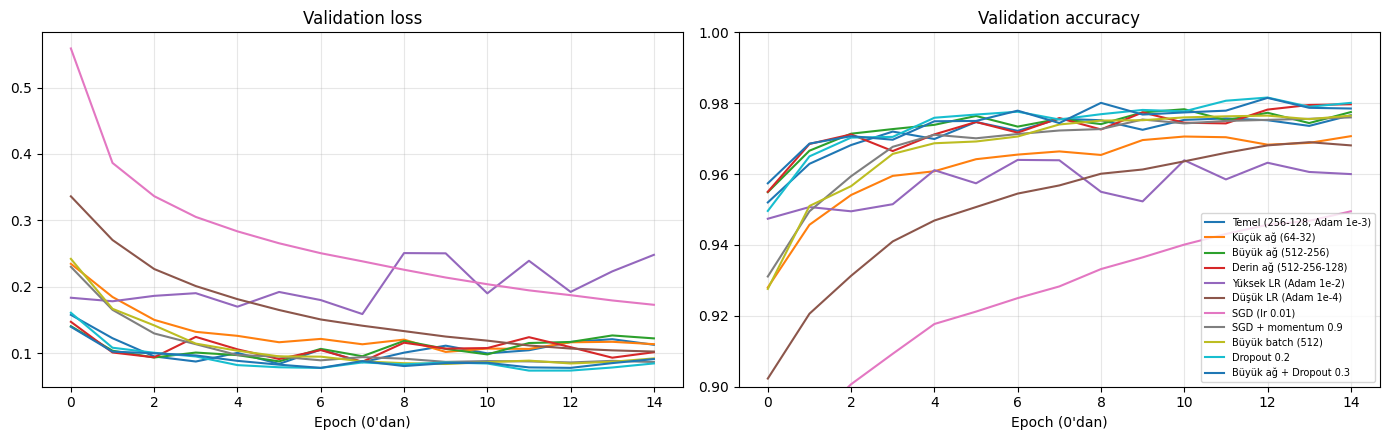

In [8]:
header = f"{'Yapılandırma':<30}{'Param':>10}{'Epoch':>7}{'TrLoss':>8}{'VaLoss':>8}{'TrAcc':>8}{'VaAcc':>8}{'TeAcc':>8}{'Süre(s)':>9}"
print(header); print("-" * len(header))
for r in results:
    n_p = sum(p.numel() for p in r["model"].parameters())
    print(f"{r['cfg']['name']:<30}{n_p:>10,}{r['best_epoch']:>7}{r['train_loss']:>8.4f}{r['val_loss']:>8.4f}"
          f"{r['train_acc']*100:>7.2f}%{r['val_acc']*100:>7.2f}%{r['test_acc']*100:>7.2f}%{r['time']:>9.1f}")

best = max(results, key=lambda r: r["val_acc"])
best_model = best["model"]
print(f"\nValidation'a göre en iyi yapılandırma: {best['cfg']['name']} "
      f"(val {best['val_acc']*100:.2f}%, test {best['test_acc']*100:.2f}%)")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for r in results:
    ax[0].plot(r["hist"]["val_loss"], label=r["cfg"]["name"])
    ax[1].plot(r["hist"]["val_acc"], label=r["cfg"]["name"])
ax[0].set_title("Validation loss"); ax[1].set_title("Validation accuracy")
ax[1].set_ylim(0.9, 1.0)
for a in ax: a.set_xlabel("Epoch (0'dan)"); a.grid(alpha=.3)
ax[1].legend(fontsize=7, loc="lower right"); plt.tight_layout(); plt.show()

## 5. Kendi El Yazımın Hazırlanması ve Tahmin

Fotoğraf: beyaz kâğıt üzerine mavi tükenmez kalemle yazılmış okul numarası (`okulnoelyazisi.jpeg`).

MNIST formatına getirme adımları:
1. **Gri tonlamaya çevirme.**
2. **Aydınlatma düzeltme:** büyük Gaussian blur ile arka plan tahmini yapılıp görüntü bu arka plana bölünür (fotoğraftaki gölge/ışık farkı giderilir).
3. **Renk ters çevirme:** MNIST'te arka plan siyah (0), rakam beyazdır → mürekkep parlak, kâğıt 0 olur.
4. **Otsu eşikleme + bağlantılı bileşen analizi** ile rakamlar ayrı ayrı bulunur, soldan sağa sıralanır.
5. **Kalınlaştırma:** tükenmez kalem çizgisi MNIST'e göre ince olduğu için hafif dilation uygulanır.
6. **MNIST'teki gibi boyutlandırma:** rakam en-boy oranı korunarak 20×20 kutuya sığdırılır, 28×28 tuvale yerleştirilir ve kütle merkezi ortaya kaydırılır.
7. **Normalizasyon:** [0,1] → `(x - 0.1307) / 0.3081` (eğitim verisiyle aynı).

In [9]:
IMAGE_PATH = "okulnoelyazisi.jpeg"
STUDENT_NO = "23120205027"

if not os.path.exists(IMAGE_PATH):
    try:
        from google.colab import files
        print("Okul numarası fotoğrafını yükleyin:")
        IMAGE_PATH = list(files.upload().keys())[0]
    except ImportError:
        raise FileNotFoundError(f"{IMAGE_PATH} bulunamadı")
print("Görüntü:", IMAGE_PATH)

Okul numarası fotoğrafını yükleyin:


Saving okulnoelyazisi.jpeg to okulnoelyazisi.jpeg
Görüntü: okulnoelyazisi.jpeg


Bulunan rakam sayısı: 11 (beklenen: 11)


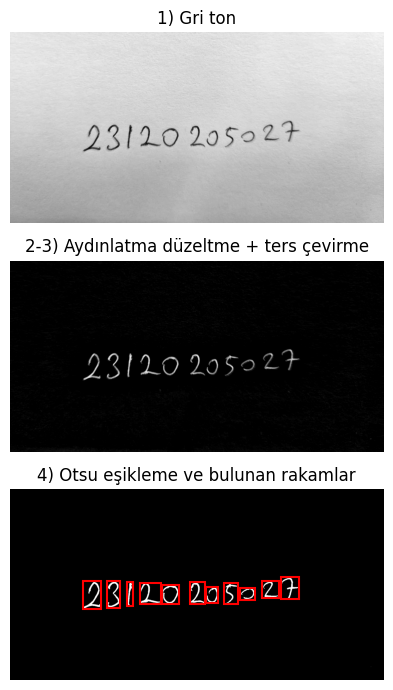

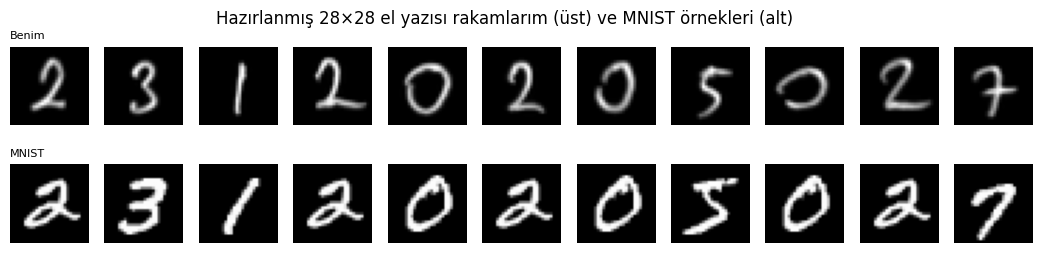

In [10]:
def otsu_threshold(x):
    hist, edges = np.histogram(x, bins=256, range=(0, 1))
    p = hist / hist.sum()
    w = np.cumsum(p)
    mu = np.cumsum(p * edges[:-1])
    between = (mu[-1] * w - mu) ** 2 / (w * (1 - w) + 1e-12)
    return edges[np.argmax(between)]


def to_mnist_style(crop):
    # crop: siyah arka plan, beyaz rakam, değerler 0..1
    h, w = crop.shape
    stroke = max(1, round(max(h, w) / 25))
    crop = ndimage.grey_dilation(crop, size=(stroke, stroke))         # çizgiyi kalınlaştır
    side = max(h, w) + 2 * stroke
    square = np.zeros((side, side), np.float32)
    y0, x0 = (side - h) // 2, (side - w) // 2
    square[y0:y0 + h, x0:x0 + w] = crop                                # en-boy oranını koru
    d20 = Image.fromarray((square * 255).astype(np.uint8)).resize((20, 20), Image.LANCZOS)
    out = np.zeros((28, 28), np.float32)
    out[4:24, 4:24] = np.asarray(d20, np.float32) / 255.0             # 20x20 → 28x28 tuval
    cy, cx = ndimage.center_of_mass(out)
    out = ndimage.shift(out, (14 - cy, 14 - cx), order=1, mode="constant")  # kütle merkezini ortala
    return np.clip(out, 0, 1)


def preprocess_number_image(path):
    gray = Image.open(path).convert("L")                               # 1) gri ton
    bg = gray.filter(ImageFilter.GaussianBlur(radius=40))              # 2) arka plan tahmini
    g = np.asarray(gray, np.float32)
    b = np.asarray(bg, np.float32) + 1e-6
    ink = np.clip(1.0 - g / b, 0, 1)                                    # 3) ters çevir: mürekkep parlak
    ink /= ink.max()

    thr = otsu_threshold(ink)                                           # 4) eşikleme
    mask = ink > thr
    labels, n = ndimage.label(ndimage.binary_dilation(mask, iterations=2))
    sizes = ndimage.sum(mask, labels, range(1, n + 1))
    objs = ndimage.find_objects(labels)
    boxes = [objs[i] for i in range(n) if sizes[i] > 0.15 * sizes.max()]   # küçük lekeleri at
    boxes.sort(key=lambda s: s[1].start)

    merged = []                                                         # aynı rakama ait parçaları birleştir
    for s in boxes:
        if merged:
            m = merged[-1]
            overlap = min(m[1].stop, s[1].stop) - max(m[1].start, s[1].start)
            if overlap > 0.5 * min(m[1].stop - m[1].start, s[1].stop - s[1].start):
                merged[-1] = (slice(min(m[0].start, s[0].start), max(m[0].stop, s[0].stop)),
                              slice(min(m[1].start, s[1].start), max(m[1].stop, s[1].stop)))
                continue
        merged.append(s)

    digits = []
    for s in merged:
        crop = ink[s] * (ink[s] > thr * 0.6)
        digits.append(to_mnist_style(crop / crop.max()))                # 5-6) MNIST biçimi
    return np.asarray(gray), ink, mask, merged, np.stack(digits)


gray, ink, mask, boxes, my_digits = preprocess_number_image(IMAGE_PATH)
print(f"Bulunan rakam sayısı: {len(my_digits)} (beklenen: {len(STUDENT_NO)})")

fig, ax = plt.subplots(3, 1, figsize=(12, 7))
ax[0].imshow(gray, cmap="gray"); ax[0].set_title("1) Gri ton")
ax[1].imshow(ink, cmap="gray");  ax[1].set_title("2-3) Aydınlatma düzeltme + ters çevirme")
ax[2].imshow(mask, cmap="gray"); ax[2].set_title("4) Otsu eşikleme ve bulunan rakamlar")
for s in boxes:
    ax[2].add_patch(plt.Rectangle((s[1].start, s[0].start), s[1].stop - s[1].start, s[0].stop - s[0].start,
                                  fill=False, edgecolor="red", lw=1.5))
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

# 28x28 rakamları kaydet (repoya eklemek için)
os.makedirs("el_yazisi_28x28", exist_ok=True)
for i, d in enumerate(my_digits):
    lbl = STUDENT_NO[i] if i < len(STUDENT_NO) else "x"
    Image.fromarray((d * 255).astype(np.uint8)).save(f"el_yazisi_28x28/{i:02d}_{lbl}.png")

# MNIST örnekleriyle yan yana karşılaştırma
fig, axes = plt.subplots(2, len(my_digits), figsize=(1.2 * len(my_digits), 2.8))
for i, d in enumerate(my_digits):
    axes[0, i].imshow(d, cmap="gray"); axes[0, i].axis("off")
    lbl = int(STUDENT_NO[i]) if i < len(STUDENT_NO) else 0
    j = (y_full == lbl).nonzero()[0].item()
    axes[1, i].imshow(train_full.data[j], cmap="gray"); axes[1, i].axis("off")
axes[0, 0].set_title("Benim", fontsize=8, loc="left"); axes[1, 0].set_title("MNIST", fontsize=8, loc="left")
plt.suptitle("Hazırlanmış 28×28 el yazısı rakamlarım (üst) ve MNIST örnekleri (alt)"); plt.show()

[Deney 1 – Temel MLP]
  Gerçek  : 23120205027
  Tahmin  : 23120205727
  Doğru   : 10/11  (90.9%)


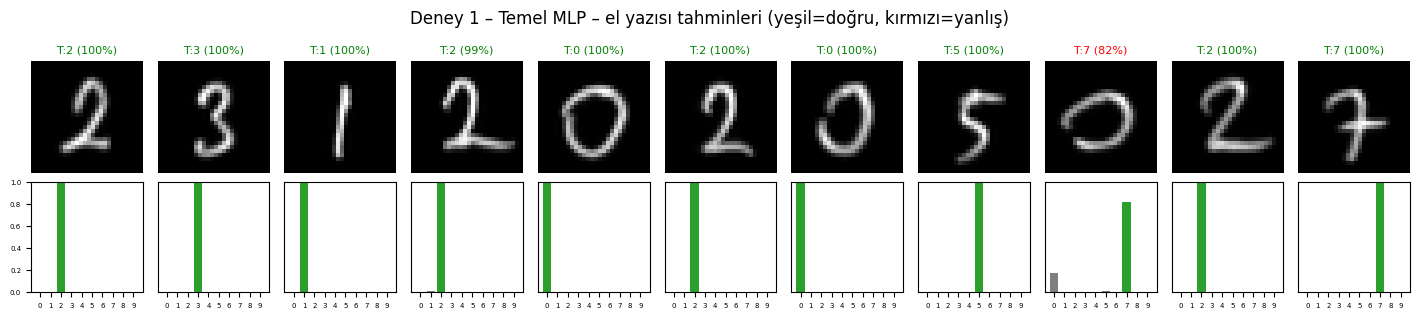

[Deney 2 en iyi – Dropout 0.2]
  Gerçek  : 23120205027
  Tahmin  : 23120205027
  Doğru   : 11/11  (100.0%)


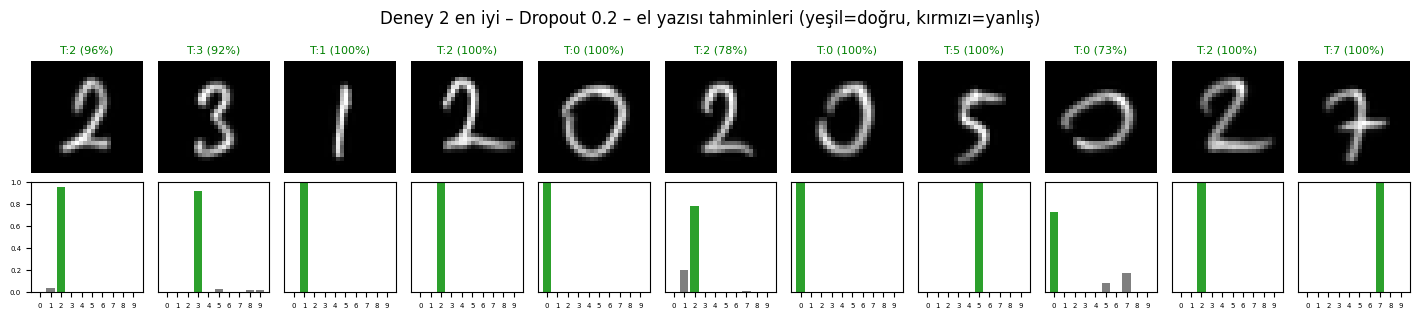

In [11]:
X_my = torch.tensor((my_digits - MNIST_MEAN) / MNIST_STD, dtype=torch.float32).view(len(my_digits), -1).to(device)  # 7) normalizasyon
true_digits = [int(c) for c in STUDENT_NO]

@torch.no_grad()
def predict_my_digits(model, title):
    model.eval()
    probs = F.softmax(model(X_my), dim=1).cpu().numpy()
    preds = probs.argmax(1)
    n = min(len(preds), len(true_digits))
    correct = sum(int(preds[i] == true_digits[i]) for i in range(n))
    print(f"[{title}]")
    print("  Gerçek  :", "".join(map(str, true_digits)))
    print("  Tahmin  :", "".join(map(str, preds)))
    print(f"  Doğru   : {correct}/{len(true_digits)}  ({correct/len(true_digits)*100:.1f}%)")

    fig, axes = plt.subplots(2, len(preds), figsize=(1.3 * len(preds), 3.2),
                             gridspec_kw=dict(height_ratios=[1.2, 1]))
    for i, p in enumerate(preds):
        ok = i < len(true_digits) and p == true_digits[i]
        axes[0, i].imshow(my_digits[i], cmap="gray"); axes[0, i].axis("off")
        axes[0, i].set_title(f"T:{p} ({probs[i, p]*100:.0f}%)", fontsize=8, color="green" if ok else "red")
        axes[1, i].bar(range(10), probs[i], color=["tab:green" if k == p else "tab:gray" for k in range(10)])
        axes[1, i].set_xticks(range(10)); axes[1, i].tick_params(labelsize=5); axes[1, i].set_ylim(0, 1)
        if i: axes[1, i].set_yticks([])
    plt.suptitle(f"{title} – el yazısı tahminleri (yeşil=doğru, kırmızı=yanlış)"); plt.tight_layout(); plt.show()
    return correct

c1 = predict_my_digits(base_model, "Deney 1 – Temel MLP")
c2 = predict_my_digits(best_model, f"Deney 2 en iyi – {best['cfg']['name']}")

## 6. Özet Tablo (README için)

In [12]:
print("| Model | Val Acc | Test Acc | El yazısı doğruluğu | Eğitim süresi |")
print("|---|---|---|---|---|")
print(f"| Deney 1 – Temel MLP | {base_hist['val_acc'][base_best_epoch-1]*100:.2f}% | {base_test_acc*100:.2f}% | "
      f"{c1}/{len(true_digits)} | {base_time:.1f} sn |")
print(f"| Deney 2 en iyi – {best['cfg']['name']} | {best['val_acc']*100:.2f}% | {best['test_acc']*100:.2f}% | "
      f"{c2}/{len(true_digits)} | {best['time']:.1f} sn |")

# İstenirse işlenmiş görüntüleri indir (repoya koymak için)
try:
    import shutil
    from google.colab import files
    shutil.make_archive("el_yazisi_28x28", "zip", "el_yazisi_28x28")
    files.download("el_yazisi_28x28.zip")
except ImportError:
    pass

| Model | Val Acc | Test Acc | El yazısı doğruluğu | Eğitim süresi |
|---|---|---|---|---|
| Deney 1 – Temel MLP | 97.82% | 97.94% | 10/11 | 14.1 sn |
| Deney 2 en iyi – Dropout 0.2 | 98.16% | 98.18% | 11/11 | 10.5 sn |


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>